# <b> Felis Taxonomy Image Classification </b>
### <b>Name</b>: <i>Harichandhana.P</i>
### <b>School</b>: <i>CDS</i>


In [ ]:
import tensorflow as tf
print(tf.__version__)

from tensorflow import keras
tf.random.set_seed(42)

import numpy as np
np.random.seed(42)

import matplotlib.pyplot as plt
%matplotlib inline

2.15.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# load numpy array from npy file
from numpy import load

X_train_std = load('/content/drive/MyDrive/Models/X_train_std.npy')
X_test_std = load('/content/drive/MyDrive/Models/X_test_std.npy')

y_train = load('/content/drive/MyDrive/Models/y_train.npy')
y_test = load('/content/drive/MyDrive/Models/y_test.npy')

In [ ]:
print("X_train_std_shape: {}".format(X_train_std.shape))
print("X_test_std_shape: {}".format(X_test_std.shape))

X_train_std_shape: (389, 224, 224, 3)
X_test_std_shape: (130, 224, 224, 3)


In [ ]:
# Load the saved best model

model_FineTune = keras.models.load_model('/content/drive/MyDrive/Models/01_DenseNet121_TransferLearning_Best_Model.h5')

In [ ]:
model_FineTune.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, None, None, 3)]      0         []                            
                                                                                                  
 zero_padding2d (ZeroPaddin  (None, None, None, 3)        0         ['input_1[0][0]']             
 g2D)                                                                                             
                                                                                                  
 conv1/conv (Conv2D)         (None, None, None, 64)       9408      ['zero_padding2d[0][0]']      
                                                                                                  
 conv1/bn (BatchNormalizati  (None, None, None, 64)       256       ['conv1/conv[0][0]']      

In [ ]:
# Total number of layers in the model
total_layers = len(model_FineTune.layers)

# Calculate the index to split the layers (35% of the total layers)
split_index = int(0.35 * total_layers)

# Freeze the initial layers up to the calculated split index
for layer in model_FineTune.layers[:split_index]:
    layer.trainable = False

# Unfreeze the remaining layers
for layer in model_FineTune.layers[split_index:]:
    layer.trainable = True

In [ ]:
model_FineTune.compile(loss='sparse_categorical_crossentropy',
                 optimizer='adam',
                 metrics=['accuracy'])

callbacks_FineTune = [
             keras.callbacks.ModelCheckpoint("bestFT.h5",
                                             monitor='val_accuracy',
                                             save_weights_only=True,
                                             save_best_only=True)
]

history_FineTune = model_FineTune.fit(x = X_train_std, y = y_train, epochs=10,
                                      validation_split=0.1, batch_size=32, callbacks=callbacks_FineTune)

Epoch 1/10
11/11 [==============================] - 42s 500ms/step - loss: 0.0064 - accuracy: 1.0000 - val_loss: 3.1685 - val_accuracy: 0.7692
Epoch 2/10
11/11 [==============================] - 2s 173ms/step - loss: 0.0979 - accuracy: 0.9800 - val_loss: 5.0169 - val_accuracy: 0.6923
Epoch 3/10
11/11 [==============================] - 2s 182ms/step - loss: 0.0550 - accuracy: 0.9857 - val_loss: 6.0629 - val_accuracy: 0.7436
Epoch 4/10
11/11 [==============================] - 2s 187ms/step - loss: 0.0556 - accuracy: 0.9829 - val_loss: 3.7137 - val_accuracy: 0.7436
Epoch 5/10
11/11 [==============================] - 2s 181ms/step - loss: 0.0730 - accuracy: 0.9714 - val_loss: 2.6080 - val_accuracy: 0.7436
Epoch 6/10
11/11 [==============================] - 2s 230ms/step - loss: 0.0803 - accuracy: 0.9686 - val_loss: 3.2868 - val_accuracy: 0.7949
Epoch 7/10
11/11 [==============================] - 2s 230ms/step - loss: 0.0695 - accuracy: 0.9829 - val_loss: 2.8747 - val_accuracy: 0.8205
Epoch

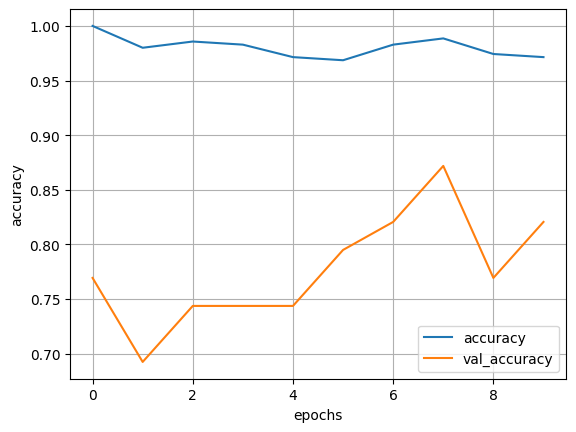

In [ ]:
keys = ['accuracy', 'val_accuracy']
progress = {k:v for k,v in history_FineTune.history.items() if k in keys}

import pandas as pd
pd.DataFrame(progress).plot()

plt.xlabel("epochs")
plt.ylabel("accuracy")

plt.grid(True)
plt.show()

In [ ]:
testLoss_FineTune, testAccuracy_FineTune = model_FineTune.evaluate(x = X_test_std, y = y_test)
print("Test-loss: %f, Test-accuracy: %f" % (testLoss_FineTune, testAccuracy_FineTune))

5/5 [==============================] - 0s 72ms/step - loss: 4.5669 - accuracy: 0.6385
Test-loss: 4.566948, Test-accuracy: 0.638462


In [ ]:
model_FineTune.load_weights("bestFT.h5")

testLoss_FineTune, testAccuracy_FineTune = model_FineTune.evaluate(x = X_test_std, y = y_test)

print("Test-loss: %f, Test-accuracy: %f" % (testLoss_FineTune, testAccuracy_FineTune))

5/5 [==============================] - 0s 71ms/step - loss: 4.3210 - accuracy: 0.6538
Test-loss: 4.320967, Test-accuracy: 0.653846


In [ ]:
cProba = model_FineTune.predict(X_test_std)

5/5 [==============================] - 2s 100ms/step


In [ ]:
cLabel = np.argmax(cProba, axis=-1)

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
confusion_matrix(y_true = y_test, y_pred = cLabel)

array([[10,  0,  0,  4,  3,  2,  4],
       [ 2, 16,  0,  2,  0,  0,  0],
       [ 1,  0,  4,  0,  1,  1,  3],
       [ 1,  0,  0, 11,  2,  1,  1],
       [ 0,  0,  0,  4, 11,  3,  3],
       [ 2,  0,  0,  1,  0, 15,  4],
       [ 0,  0,  0,  0,  0,  0, 18]])

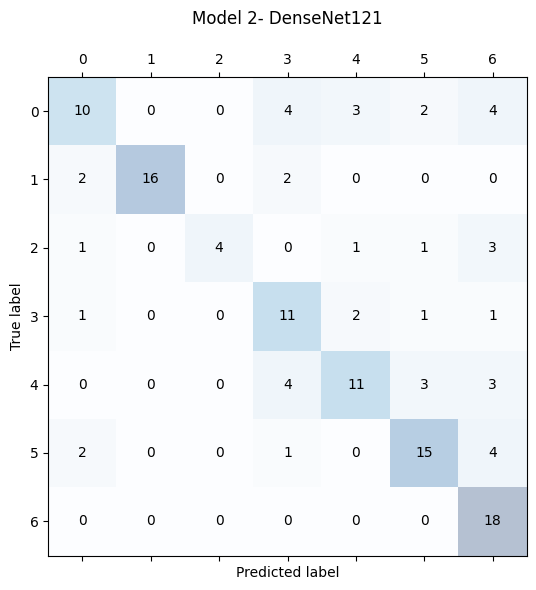

In [ ]:
cm = confusion_matrix(y_true = y_test, y_pred = cLabel)

fig, ax = plt.subplots(figsize=(6, 6))
ax.matshow(cm, cmap=plt.cm.Blues, alpha=0.3)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(x=j, y=i, s=cm[i, j], va='center', ha='center')

ax.title.set_text('Model 2- DenseNet121\n')
plt.xlabel('Predicted label')
plt.ylabel('True label')

plt.tight_layout()
plt.savefig("ConfusionMatrix.png", dpi=300, format='png', pad_inches=0.3)
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

pScore = precision_score(y_true= y_test, y_pred = cLabel, average = 'weighted')
print("Precision: ", pScore)

rScore = recall_score(y_true= y_test, y_pred = cLabel, average = 'weighted')
print("Recall: ", rScore)

fScore = f1_score(y_true= y_test, y_pred = cLabel, average = 'weighted')
print("F1-score: ", fScore)

print("\n\n\n")

Precision:  0.6983185931715343
Recall:  0.6538461538461539
F1-score:  0.6493374636265801






In [ ]:
# Saves the best model obtained
model_FineTune.save('/content/drive/MyDrive/Models/02_DenseNet121_FineTuned_Best_Model.h5')

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(
